In [1]:
from pathlib import Path
from typing import Any, Dict, List
import json
import statistics

from transformers import AutoTokenizer

DATA_DIR = Path("benchmarks_2") / "bird" / "format_data"
MODEL_NAME = "Qwen/Qwen3-0.6B"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True,
)


def read_jsonl_file(path: Path) -> List[Dict[str, Any]]:
    with path.open("r", encoding="utf-8") as file:
        return [json.loads(line) for line in file if line.strip()]


d:\GitHub\text2sql_distillation_draft\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
raw_train_data = read_jsonl_file(DATA_DIR / "train.jsonl")
raw_val_data = read_jsonl_file(DATA_DIR / "val.jsonl")

{
    "train_rows": len(raw_train_data),
    "val_rows": len(raw_val_data),
    "train_keys": sorted(raw_train_data[0].keys()),
    "val_keys": sorted(raw_val_data[0].keys()),
    "train_has_evidence": "EVIDENCE:" in raw_train_data[0]["user_prompt"],
    "val_has_evidence": "EVIDENCE:" in raw_val_data[0]["user_prompt"],
}


{'train_rows': 9428,
 'val_rows': 1534,
 'train_keys': ['response', 'system_prompt', 'user_prompt'],
 'val_keys': ['response', 'system_prompt', 'user_prompt'],
 'train_has_evidence': True,
 'val_has_evidence': True}

In [3]:
def get_prompt_text(tokenizer, system_prompt: str, user_prompt: str, enable_thinking: bool = False) -> str:
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt},
    ]
    try:
        return tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
            enable_thinking=enable_thinking,
        )
    except TypeError:
        return tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
        )


def token_length(tokenizer, text: str) -> int:
    inputs = tokenizer(text, return_tensors="pt")
    return inputs["input_ids"].shape[-1]


def summarize_lengths(lengths: List[int]) -> Dict[str, Any]:
    if not lengths:
        return {}

    lengths_sorted = sorted(lengths)
    n = len(lengths_sorted)

    def percentile(p: float) -> float:
        if n == 1:
            return float(lengths_sorted[0])
        idx = (n - 1) * p
        low = int(idx)
        high = min(low + 1, n - 1)
        frac = idx - low
        return lengths_sorted[low] * (1 - frac) + lengths_sorted[high] * frac

    return {
        "count": n,
        "min": min(lengths_sorted),
        "max": max(lengths_sorted),
        "mean": statistics.mean(lengths_sorted),
        "median": statistics.median(lengths_sorted),
        "p90": percentile(0.90),
        "p95": percentile(0.95),
        "p99": percentile(0.99),
    }


def extract_prompt_block(user_prompt: str, header: str) -> str:
    marker = f"{header}:\n"
    if marker not in user_prompt:
        return ""
    start = user_prompt.index(marker) + len(marker)
    next_headers = ["\n\nQUESTION:\n", "\n\nEVIDENCE:\n", "\n\nSCHEMA:\n"]
    ends = [user_prompt.find(candidate, start) for candidate in next_headers]
    ends = [end for end in ends if end != -1]
    end = min(ends) if ends else len(user_prompt)
    return user_prompt[start:end].strip()


In [4]:
from tqdm.auto import tqdm


def analyze_dataset_token_lengths(
    dataset: List[Dict[str, Any]],
    tokenizer,
    split_name: str,
    enable_thinking: bool = False,
):
    prompt_lengths = []
    prompt_plus_response_lengths = []
    response_only_lengths = []
    results = []

    for i, item in tqdm(enumerate(dataset), total=len(dataset), desc=f"Analyze {split_name}"):
        prompt_text = get_prompt_text(
            tokenizer=tokenizer,
            system_prompt=item["system_prompt"],
            user_prompt=item["user_prompt"],
            enable_thinking=enable_thinking,
        )
        response_text = item["response"]

        prompt_len = token_length(tokenizer, prompt_text)
        full_len = token_length(tokenizer, prompt_text + response_text)
        response_len = full_len - prompt_len

        prompt_lengths.append(prompt_len)
        prompt_plus_response_lengths.append(full_len)
        response_only_lengths.append(response_len)

        results.append(
            {
                "split": split_name,
                "idx": i,
                "question": extract_prompt_block(item["user_prompt"], "QUESTION"),
                "evidence": extract_prompt_block(item["user_prompt"], "EVIDENCE"),
                "prompt_len": prompt_len,
                "prompt_plus_response_len": full_len,
                "response_len_only": response_len,
            }
        )

    summary = {
        "prompt_only": summarize_lengths(prompt_lengths),
        "response_only": summarize_lengths(response_only_lengths),
        "prompt_plus_response": summarize_lengths(prompt_plus_response_lengths),
    }

    return results, summary


In [5]:
train_results, train_summary = analyze_dataset_token_lengths(
    raw_train_data,
    tokenizer,
    split_name="train",
    enable_thinking=False,
)
val_results, val_summary = analyze_dataset_token_lengths(
    raw_val_data,
    tokenizer,
    split_name="val",
    enable_thinking=False,
)

results_by_split = {
    "train": train_results,
    "val": val_results,
}
summary = {
    "train": train_summary,
    "val": val_summary,
}
summary


Analyze val: 100%|██████████| 1534/1534 [00:07<00:00, 200.58it/s]


{'train': {'prompt_only': {'count': 9428,
   'min': 324,
   'max': 2912,
   'mean': 711.2855324565126,
   'median': 567.0,
   'p90': 999.0,
   'p95': 2796.0,
   'p99': 2840.0},
  'response_only': {'count': 9428,
   'min': 9,
   'max': 299,
   'mean': 56.91228256257955,
   'median': 55.0,
   'p90': 87.0,
   'p95': 99.0,
   'p99': 133.0},
  'prompt_plus_response': {'count': 9428,
   'min': 339,
   'max': 3001,
   'mean': 768.1978150190921,
   'median': 628.0,
   'p90': 1051.0,
   'p95': 2815.5999999999985,
   'p99': 2907.0}},
 'val': {'prompt_only': {'count': 1534,
   'min': 372,
   'max': 1633,
   'mean': 694.5560625814863,
   'median': 627.5,
   'p90': 829.7,
   'p95': 1519.35,
   'p99': 1560.0},
  'response_only': {'count': 1534,
   'min': 12,
   'max': 546,
   'mean': 56.46414602346806,
   'median': 53.0,
   'p90': 82.70000000000005,
   'p95': 92.34999999999991,
   'p99': 146.67000000000007},
  'prompt_plus_response': {'count': 1534,
   'min': 404,
   'max': 1784,
   'mean': 751.0202

In [6]:
summary


{'train': {'prompt_only': {'count': 9428,
   'min': 324,
   'max': 2912,
   'mean': 711.2855324565126,
   'median': 567.0,
   'p90': 999.0,
   'p95': 2796.0,
   'p99': 2840.0},
  'response_only': {'count': 9428,
   'min': 9,
   'max': 299,
   'mean': 56.91228256257955,
   'median': 55.0,
   'p90': 87.0,
   'p95': 99.0,
   'p99': 133.0},
  'prompt_plus_response': {'count': 9428,
   'min': 339,
   'max': 3001,
   'mean': 768.1978150190921,
   'median': 628.0,
   'p90': 1051.0,
   'p95': 2815.5999999999985,
   'p99': 2907.0}},
 'val': {'prompt_only': {'count': 1534,
   'min': 372,
   'max': 1633,
   'mean': 694.5560625814863,
   'median': 627.5,
   'p90': 829.7,
   'p95': 1519.35,
   'p99': 1560.0},
  'response_only': {'count': 1534,
   'min': 12,
   'max': 546,
   'mean': 56.46414602346806,
   'median': 53.0,
   'p90': 82.70000000000005,
   'p95': 92.34999999999991,
   'p99': 146.67000000000007},
  'prompt_plus_response': {'count': 1534,
   'min': 404,
   'max': 1784,
   'mean': 751.0202

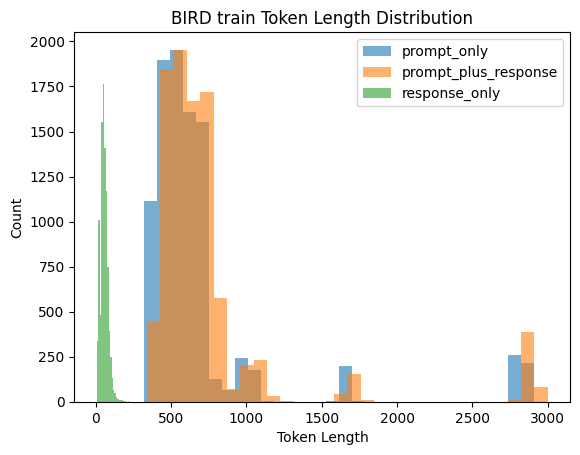

In [7]:
import matplotlib.pyplot as plt

selected_split = "train"  # change to "val" when needed
results = results_by_split[selected_split]

prompt_lens = [x["prompt_len"] for x in results]
full_lens = [x["prompt_plus_response_len"] for x in results]
response_lens = [x["response_len_only"] for x in results]

plt.figure()
plt.hist(prompt_lens, bins=30, alpha=0.6, label="prompt_only")
plt.hist(full_lens, bins=30, alpha=0.6, label="prompt_plus_response")
plt.hist(response_lens, bins=30, alpha=0.6, label="response_only")

plt.xlabel("Token Length")
plt.ylabel("Count")
plt.title(f"BIRD {selected_split} Token Length Distribution")
plt.legend()
plt.show()


In [8]:
selected_split = "train"  # change to "val" when needed
sorted(
    results_by_split[selected_split],
    key=lambda x: x["prompt_plus_response_len"],
    reverse=True,
)[:10]


[{'split': 'train',
  'idx': 7077,
  'question': 'Among the employees who are married and wish to receive e-mail promotions, how much higher is their highest pay rate from the average pay rate?',
  'evidence': "married refers to MaritalStatus = 'M'; Contact does wish to receive e-mail promotions from Adventure Works refers to EmailPromotion = 1; Average = Divide (Sum(Rate (MaritalStatus = 'M' & EmailPromotion = 1))), Count (BusinessEntityID (MaritalStatus = 'M' & EmailPromotion = 1)); MAX(Rate (MaritalStatus = 'M' & EmailPromotion = 1) - Average;",
  'prompt_len': 2912,
  'prompt_plus_response_len': 3001,
  'response_len_only': 89},
 {'split': 'train',
  'idx': 7091,
  'question': 'What is the credit rating of the company whose average lead time is 16 days for a standard price of 18.9900 and whose last receipt date is August 27, 2011?',
  'evidence': "last receipt date is August 17, 2011 refers to LastReceiptDate> = '2011-08-17 00:00:00' and LastReceiptDate < '2011-08-18 00:00:00';",
 